In [ ]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

In [41]:
import sys
!{sys.executable} -m pip install openpyxl

  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
Using cached openpyxl-3.1.5-py2.py3-none-any.whl (250 kB)
Using cached et_xmlfile-2.0.0-py3-none-any.whl (18 kB)


### Logboek casus A - Vincent de Jong

16-11-2026

Vandaag gedaan: We hebben als eerste een dataset gevonden: https://causeweb.org/tshs/tumor-growth/

Deze dataset bevat metingen van de tumorgroei van een paar muizen voor een experiment, met kolommen voor het ID van die dieren en dan de tijd dat er gemeten werd, die dan overeenkomen om de volume van de tumor die gemeten is te weergeven. Er zijn 4 groepen, (controle, drug, radiation en drug + radiation) maar ik denk dat we voor deze casus hier geen onderscheid voor hoeven te maken. Een paar dagen zijn niet gemeten, maar er zijn genoeg metingen dat ik denk dat we er niet erg veel last van zullen hebben of dat het daardoor onbruikbaar is geworden. Git doet het op linux heel erg moeilijk, dus ik laat het hierbij voor vandaag.

Voor morgen: Eerst de data analyseren door middel van een plotje, kijken hoe de groei eruit ziet enzomet een vergelijking misschien? Daarna kijken of de code voor al die modellen toegepast kan worden op de data. De eerste zes lijken mij allemaalmakkelijk genoeg om te implementeren. Ik en Fleur zullen dan ieder een solver maken.

______________________

18-11-2026

Vandaag gedaan: Ik ga nu eerst een korte analyse doen op de data. Jupyter doet moelijk en ik kan opeens niet naar code buiten dit mapje referen, dus ik kloon het excelsheet even en open het in dit logboek.


In [42]:
data = pd.read_excel("tumorgrowthlogboek.xlsx")
print(data)

   Unnamed: 0  CONTROL  Unnamed: 2  Unnamed: 3  Unnamed: 4  Unnamed: 5  \
0         Day    101.0       102.0       103.0       104.0       105.0   
1           0     41.8        79.4        44.8        67.7        54.7   
2           1      NaN       110.3        67.5        92.4         NaN   
3           2      NaN         NaN        55.8        77.7         NaN   
4           3     85.0         NaN        82.8       107.4        61.1   
5           4    114.0       201.3       106.8       147.1        75.3   
6           5    162.3       255.3         NaN         NaN       112.5   
7           6    178.3       349.1         NaN         NaN       117.8   
8           7    325.0       357.5       309.5       226.1       164.9   
9           8      NaN       670.0       355.9       285.3         NaN   
10          9      NaN         NaN       554.8       541.5         NaN   
11         10    623.7         NaN       740.4       551.9       816.2   
12         11    648.4       624.3    

De leesbaarheid buiten het excelsheet valt smerig tegen. Ik hoeft niet van alle muizen de data te zien dus ik filter even alle muizen behalve die van de controle eruit.

In [44]:
data = pd.read_excel("tumorgrowthlogboek.xlsx", header=1)

# Alleen de controlemuizen selecteren
controle = data[["Day", 101, 102, 103, 104, 105, 106, 107, 108]]

print(controle)

    Day     101     102     103     104     105     106     107     108
0     0    41.8    79.4    44.8    67.7    54.7    60.0    46.8    49.4
1     1     NaN   110.3    67.5    92.4     NaN    74.2     NaN     NaN
2     2     NaN     NaN    55.8    77.7     NaN    98.9     NaN     NaN
3     3    85.0     NaN    82.8   107.4    61.1   103.3     NaN     NaN
4     4   114.0   201.3   106.8   147.1    75.3   106.4   162.6   123.2
5     5   162.3   255.3     NaN     NaN   112.5     NaN   264.5   286.5
6     6   178.3   349.1     NaN     NaN   117.8     NaN   253.1   484.9
7     7   325.0   357.5   309.5   226.1   164.9   166.3   419.3   584.5
8     8     NaN   670.0   355.9   285.3     NaN   269.2     NaN     NaN
9     9     NaN     NaN   554.8   541.5     NaN   478.4     NaN     NaN
10   10   623.7     NaN   740.4   551.9   816.2   356.4     NaN     NaN
11   11   648.4   624.3  1012.1   609.8   846.4   498.8  1273.5  1581.9
12   12   835.9   640.6     NaN     NaN  1403.6     NaN  1712.0 

Dat is beter. Om de groei van de tumor van zo'n muis te bekijken, ga ik de tumorvolume en tijdstip in een simpel plotje doen. Ik sla hiervoor de waarden van muis 1 in wat lists.

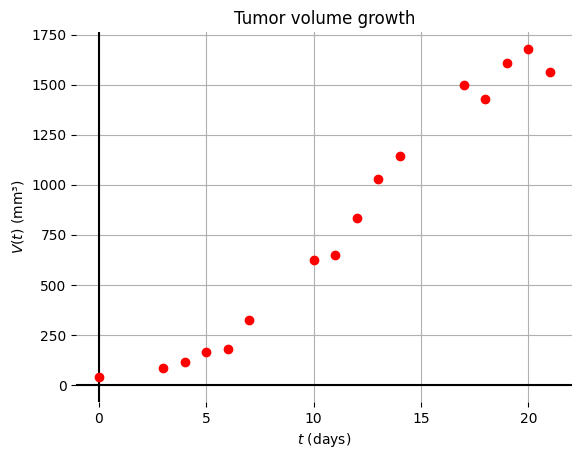

In [21]:
ts = [0, 3, 4, 5, 6, 7, 10, 11, 12, 13, 14, 17, 18, 19, 20, 21]
Vs = [41.8, 85, 114, 162.3, 178.3, 325, 623.7, 648.4, 835.9, 1030.4, 1141.8, 1499.9, 1429.3, 1609.3, 1678.3, 1564]
dt = min(np.diff(ts)) / 10
V0 = Vs[0]
t_start = ts[0]
t_end = ts[-1]

pd.DataFrame({'$t$': ts, '$V$': Vs}).T

plt.axhline(0.0, color='k'); plt.axvline(0.0, color='k')
plt.plot(ts, Vs, 'or')
plt.title('Tumor volume growth'); plt.xlabel('$t$ (days)'); plt.ylabel('$V(t)$ (mm³)')
plt.grid(True); plt.box(False)
plt.show()

Je ziet dat op dag 3 de groei van de tumor aan het begin best sloom verloopt, en dat pas op dag 7 er echt dikke stijging in komt. Op dag 18 krimpt de tumor voor een dag, voordat het weer groeit op dag 19 en z'n hoogst gemeten punt bereikt op dag 20. Op de laatste dag, dag 21, krimt het echter weer.

We hebben een tumor_models map aangemaakt, waar we alle .py bestanden gaan inzetten. Hierin hebben we de differentiaalvergelijkingen die we willen gebruiken uitgewerkt.

In [18]:
def exponential(V, c):
    return c * V

def linear(V, c):
    return c

def mendelsohn(V, c, d):
    return c * V**d

def exponential_smooth(V, c, Vmax):
    return c * (Vmax - V)

def logistic(V, c, Vmax):
    return c * V * (Vmax - V)

def montroll(V, c, d, Vmax):
    return c * V * (Vmax**d - V**d)

def allee_effect(V, c, Vmin, Vmax):
    return c * (V - Vmin) * (Vmax - V)

Bij lineare groei neemt de hoeveelheid met elke tijdseenheid met een vast aantal toe.

De groei is exponentiële groei als het afhankelijk is van de huidige hoeveelheid, de groei wordt groter dermate de hoeveelheid toeneemt. Als deze groei uiteindelijk steeds verder afneemt, is het exponentiëel afvlakkend.

Met mendelsohn bepaalt de waarde van een machtsfunctie hoe sterk de exponentiële groei is.

Bij logistische groei is de volume in het begin snel aan het groeien. Naarmate de hoeveelheid dichter bij de maximale capaciteit komt, neemt de groei snel af.

De logistische groei kan je combineren met mendelsohn groei voor montroll groei. De groei is afhankelijk van de huidige hoeveelheid, maar wordt afgeremd wanneer de volume richting de max gaat.

Als laatste hebben wij gekozen voor allee groei. Hier groeit de volume alleen als het een minimale grootte is om positieve groei mogelijk te maken.

Om de groeimodellen toe te passen op onze tumordata, moeten we die wel numeriek oplossen over verschillende tijdstippen. Hiervoor gaan we een euler methode en een huenn methode toepassen.

Ik heb hiervoor de heun solver gemaakt, waar de groeisnelheid aan het begin van de stap wordt berekent, en daarna een tijdelijk stap maakt om aan het einde daarvan de geschatte groeisnelheid ook te berekenen.Op basis van die twee stappen zou heun dan een gemiddelde definitieve stap berekenen.

In [22]:
def heun_solver(model, V0, t_start, t_end, dt, parameters):

    t = t_start
    V = V0
    times = [t]
    volumes = [V]

    while t < t_end:
        step = min(dt, t_end - t)

        growth1 = model(V, *parameters)
        t1 = t + step
        V1 = V + growth1 * step
        growth2 = model(V1, *parameters)

        t = t + step

        V = V + (growth1 + growth2) / 2 * step


        times.append(t)
        volumes.append(V)

    return times, volumes

Om te kijken of dit wat heeft gedaan, heb ik ook snel een plotje gemaakt. Ik weet nu niet even snel hoe ik dit groeiparameter mee moet geven, dus ik gebruik hiervoor wel een dummywaarde.

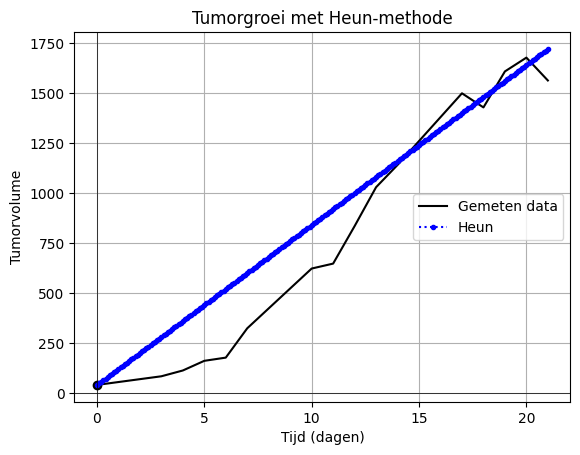

In [30]:
c = 80
t_heun, v_heun = heun_solver(linear, V0, t_start, t_end, dt, (c,))

plt.plot(ts, Vs, '-k', label='Gemeten data')
plt.plot(ts[0], Vs[0], 'ok')
plt.plot(t_heun, v_heun, '.:b', label='Heun')

plt.axhline(0.0, lw=0.5, color='k')
plt.axvline(0.0, lw=0.5, color='k')

plt.grid(True)
plt.legend()
plt.xlabel('Tijd (dagen)')
plt.ylabel('Tumorvolume')
plt.title('Tumorgroei met Heun-methode')
plt.show()

Nou, dit zou dan de resultaat van heun moeten zijn op de eerste muis. Hij loopt niet echt gelijk aan de exact, maar dat zou kunnen omdat dit een linear model is. Ik ga ook even kijken naar de resultaten van andere modellen om te zien of nu niet elke keer er gewoon een standaard resultaat uitkomt. Omdat ik ook geen d of Vmax/min heb, geef ik daarvoor nu ook even nog wat dummywaardes mee.

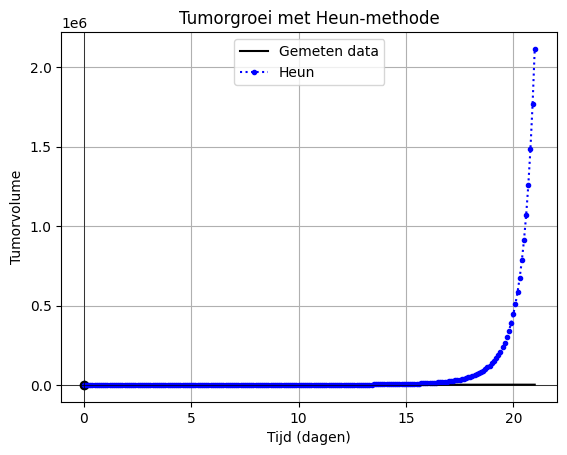

In [59]:
c = 0.1
d = 1.2
t_heun, v_heun = heun_solver(mendelsohn, V0, t_start, t_end, dt, (c, d, ))

plt.plot(ts, Vs, '-k', label='Gemeten data')
plt.plot(ts[0], Vs[0], 'ok')
plt.plot(t_heun, v_heun, '.:b', label='Heun')

plt.axhline(0.0, lw=0.5, color='k')
plt.axvline(0.0, lw=0.5, color='k')

plt.grid(True)
plt.legend()
plt.xlabel('Tijd (dagen)')
plt.ylabel('Tumorvolume')
plt.title('Tumorgroei met Heun-methode')
plt.show()

Nou, dat kan niet goed gegaan zijn. Ik vermoed omdat de meegegeven waardes veels te groot zijn. Maar, dit is natuurlijk wel andere groei dan bij de lineare en exponentiële, dus de heun zelf zou goed moeten werken.

Voor morgen: De modellen optimaliseren zodat ze meer overeenkomen met de exacte data. Ook wil ik een begin maken met het accepteren van data voor het programma.

19-11-2026

22-11-2026